# Exercise 15.2 – Explore the dataset
**SCIENTIFICALLY APPROVED – TECHNICALLY VALIDATED – AWAITING MERGE.** KI-Unterstützung: Codex; wissenschaftlicher Originalreview positiv; technische Nachprüfung separat dokumentiert.

## 1. Ziel und Anforderungen
Die [offizielle Aufgabe 15.2](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/2_self_study_session2.html) verlangt: Merkmale je Fehlertyp zusammenfassend statistisch untersuchen, **mindestens zwei geeignete Visualisierungen**, Erkenntnisse und gegebenenfalls beobachtete Schwellen festhalten und mit „Subgroup failures“ der [Datensatzbeschreibung](https://www.kaggle.com/datasets/raphaelwallsberger/xai-drilling-dataset/) vergleichen. Kursseite vollständig gelesen am **21.11.2026**.

Die Aufgabe schlägt vor, so zu tun, als sei die Beschreibung unbekannt. **Sie wurde bereits in 15.1 vollständig gelesen.** Wir behaupten keine Blindanalyse: Zuerst werden konkrete Datenbefunde dargestellt, danach ausdrücklich mit den bekannten Beschreibungsangaben verglichen. Kein unabhängiger Nachweis einer zuvor unbekannten Fehlerregel.

Abnahme: unveränderte Daten und Loader aus 15.1, Statistiken für alle neun Prozessmerkmale (numerisch/ordinal und nominal passend getrennt), ID separat als Kennung, vier überlappende Untergruppen jeweils gegen Flag=0 vergleichen. Zwei lesbare Grafiken, vorsichtige Schwellenhinweise, Grenzen, frische Ausführung und Offline-HTML 900/1400 px. **Keine Modelle, Regelfunktionen oder Confusion-Matrizen aus 15.4; keine 15.3-Arbeit.**

Kaggle-Registrierung aus 15.1 bleibt offen; kein Konto angelegt. PR #18 wurde nach ausdrücklicher bedingter Autorisierung regulär integriert, ohne die formale Anforderung als erledigt auszugeben.


## 2. Daten und Methode
Unveränderter [XAI Drilling Dataset, Version 1](https://www.kaggle.com/datasets/raphaelwallsberger/xai-drilling-dataset/), R. Wallsberger, R. Knauer und S. Matzka (2023), CC BY-NC-SA 4.0. Herkunft und feste SHA256 sind in `data/raw/XAI_DRILLING_SOURCE.md` dokumentiert. Der geprüfte Loader aus 15.1 kontrolliert Originalbytes und Schema (20.000 × 15).

Für **jedes** der sieben numerischen/ordinalen Merkmale berechnen wir Anzahl, Mittelwert, Stichproben-Standardabweichung (n−1), Minimum, Quartile, Median und Maximum je Flag 0/1. Cooling [%] hat nur fünf geordnete Stufen; sein Mittelwert ist keine Aussage über gleich große technische Effekte. Für Material und Drill Bit Type berichten wir Häufigkeiten/Anteile statt bedeutungsloser Kategorienmittelwerte. ID wird separat auf Anzahl/Bereich/Eindeutigkeit geprüft und nicht als Prozessgröße interpretiert.

Die vier Untergruppen BEF/CCF/FWF/WDF werden **jeweils separat** betrachtet. Eine mehrfach markierte Zeile zählt in jeder passenden positiven Gruppe; Flag=0 bedeutet nur „dieser Fehler nicht markiert“, nicht insgesamt fehlerfrei. Alle 114 Mehrfachfehler und die aus 15.1 bekannten identischen Zeilen bleiben erhalten. Kein Training/keine Optimierung: ein TRAIN/TEST-Split würde hier die rein beschreibende Datenaufgabe unnötig verändern.

Boxplots zeigen Median und mittlere 50 %; die Whisker reichen bis 1,5 Interquartilsabstände, Ausreißerpunkte werden zur Lesbarkeit ausgeblendet, **nicht aus den Daten entfernt**. Weil Materialien verschiedene Wertebereiche besitzen, prüfen wir FWF zusätzlich innerhalb des Materials. Die zweite Grafik betrachtet WDF-Anteile in Material/Bohrertyp-Paaren.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"pyproject.toml").exists())
sys.path.insert(0,str(root))
from sessions.ch15.drilling_data import load_data,verify_file,SUBGROUPS
from sessions.ch15.exploration import summarize,NUMERIC,CATEGORICAL
output=root/"outputs/ch15/exercise_15_2"
output.mkdir(parents=True,exist_ok=True)
data=load_data()
tables=summarize(data)
for name,table in tables.items():table.to_csv(output/f"{name}.csv",index=False)
print("Originaldaten-SHA256:",verify_file())
print("Markierte Zeilen:",data[SUBGROUPS].sum().to_dict())
print("Vollständige Statistiken aller Prozessmerkmale stehen in numeric_summary.csv und categorical_summary.csv.")
selected=tables["numeric_summary"].loc[lambda t:t.Merkmal.isin([NUMERIC[0],NUMERIC[3],"Cooling [%]"]),["Fehlertyp","Flag","Merkmal","count","mean","50%","min","max"]]
display(selected.reset_index(drop=True))

Originaldaten-SHA256: e1dcc45f8821f7b96d923a253374150d5013cead40bc08b4bef33033aef0ab83
Markierte Zeilen: {'BEF': 215, 'CCF': 344, 'FWF': 278, 'WDF': 300}
Vollständige Statistiken aller Prozessmerkmale stehen in numeric_summary.csv und categorical_summary.csv.


,Fehlertyp,Flag,Merkmal,count,mean,50%,min,max
0,BEF,0,Cutting speed vc [m/min],19785.0,23.354428,22.620,16.70,31.07
1,BEF,0,Feed rate vf [mm/min],19785.0,141.131160,122.000,71.00,261.00
2,BEF,0,Cooling [%],19785.0,57.318676,50.000,0.00,100.00
3,BEF,1,Cutting speed vc [m/min],215.0,20.381581,21.850,16.33,22.00
4,BEF,1,Feed rate vf [mm/min],215.0,94.497674,91.000,62.00,166.00
5,BEF,1,Cooling [%],215.0,4.418605,0.000,0.00,25.00
6,CCF,0,Cutting speed vc [m/min],19656.0,23.366800,22.620,16.33,31.07
7,CCF,0,Feed rate vf [mm/min],19656.0,140.680861,121.000,63.00,261.00
8,CCF,0,Cooling [%],19656.0,57.144129,50.000,0.00,100.00
9,CCF,1,Cutting speed vc [m/min],344.0,20.789419,22.180,16.57,30.67


## 3. Grafische Befunde
Die ersten fünf Panels vergleichen je einen relevanten Messwert bei Flag 0/1. Das sechste zeigt FWF-Schnittgeschwindigkeit getrennt nach Material: K = Gusseisen, N = Nichteisenmetall, P = Stahl. Die Auswahl der Panels ersetzt nicht die vollständigen Statistiken; sie wurde mit Kenntnis der bereits gelesenen Beschreibung getroffen.

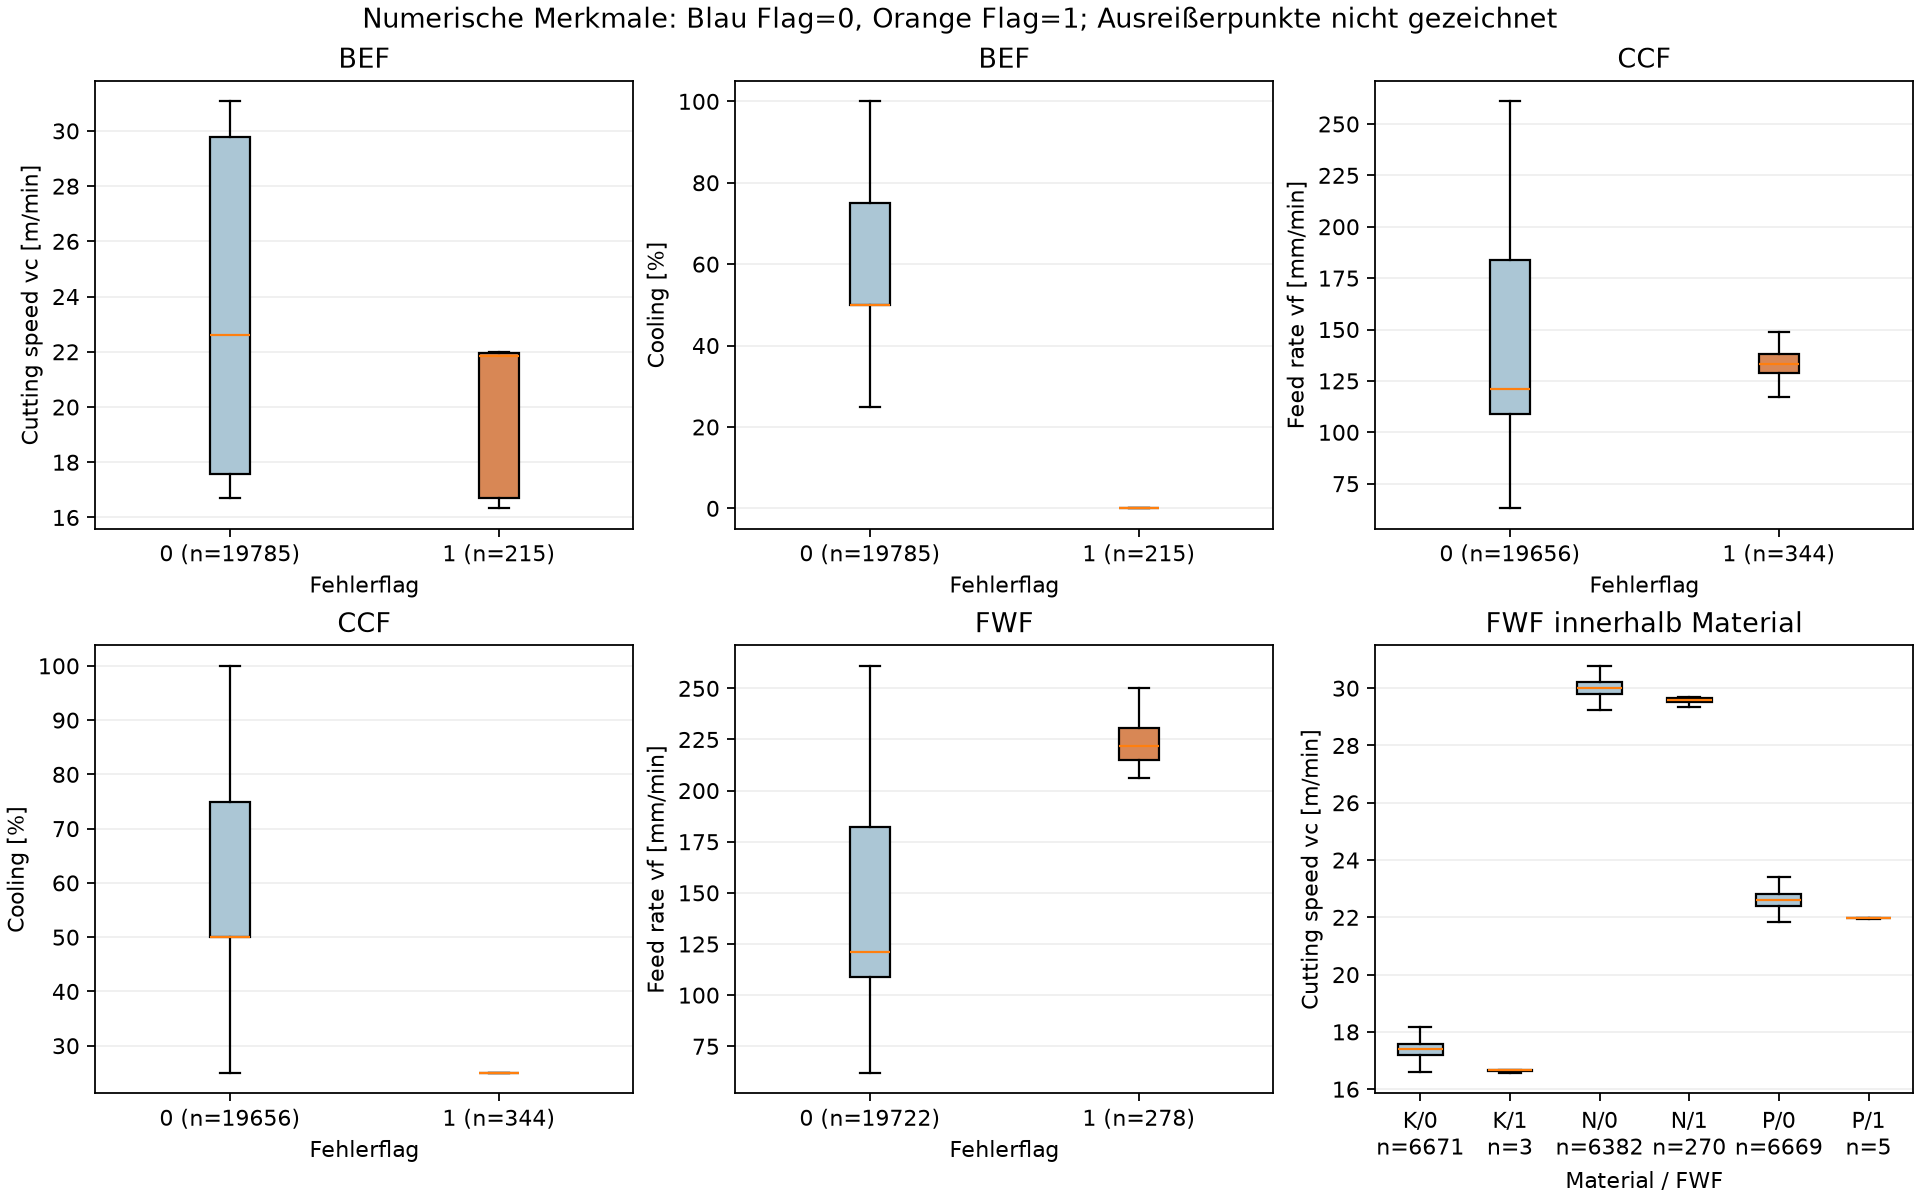

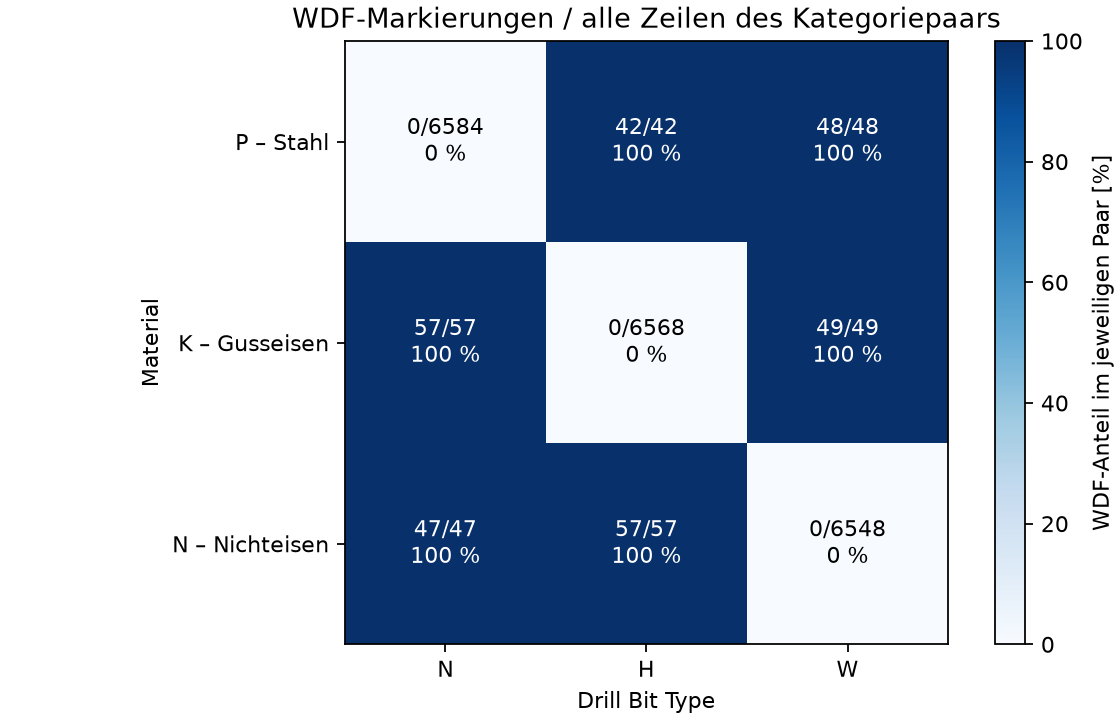

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,3,figsize=(12,7.5),layout="constrained")
specs=[("BEF",NUMERIC[0]),("BEF","Cooling [%]"),("CCF",NUMERIC[3]),("CCF","Cooling [%]"),("FWF",NUMERIC[3])]
for ax,(flag,feature) in zip(axes.flat,specs):
    groups=[data.loc[data[flag].eq(v),feature] for v in [0,1]]
    bp=ax.boxplot(groups,tick_labels=[f"0 (n={len(groups[0])})",f"1 (n={len(groups[1])})"],showfliers=False,patch_artist=True)
    for box,color in zip(bp["boxes"],["#abc6d5","#d88755"]):box.set_facecolor(color)
    ax.set(title=flag,ylabel=feature,xlabel="Fehlerflag");ax.grid(axis="y",alpha=.2)
ax=axes.flat[-1];groups=[];labels=[]
for mat in ["K","N","P"]:
    for v in [0,1]:
        part=data.loc[data.Material.eq(mat)&data.FWF.eq(v),NUMERIC[0]]
        groups.append(part);labels.append(f"{mat}/{v}\nn={len(part)}")
bp=ax.boxplot(groups,tick_labels=labels,showfliers=False,patch_artist=True)
for i,box in enumerate(bp["boxes"]):box.set_facecolor(["#abc6d5","#d88755"][i%2])
ax.set(title="FWF innerhalb Material",ylabel=NUMERIC[0],xlabel="Material / FWF");ax.grid(axis="y",alpha=.2)
fig.suptitle("Numerische Merkmale: Blau Flag=0, Orange Flag=1; Ausreißerpunkte nicht gezeichnet")
fig.savefig(output/"01_numeric_groups.png",dpi=160);plt.close(fig)
display(Image(filename=str(output/"01_numeric_groups.png")))

pairs=tables["wdf_pairs"].set_index(["Material","Drill Bit Type"])
rows=["P","K","N"];cols=["N","H","W"]
rates=np.array([[pairs.loc[(m,b),"WDF-Anteil [%]"] for b in cols] for m in rows])
fig,ax=plt.subplots(figsize=(7,4.5),layout="constrained")
im=ax.imshow(rates,vmin=0,vmax=100,cmap="Blues")
for i,m in enumerate(rows):
    for j,b in enumerate(cols):
        r=pairs.loc[(m,b)]
        ax.text(j,i,f"{int(r.WDF)}/{int(r.Zeilen)}\n{r['WDF-Anteil [%]']:.0f} %",ha="center",va="center",color="white" if rates[i,j]>50 else "black")
ax.set(xticks=range(3),xticklabels=cols,yticks=range(3),yticklabels=["P – Stahl","K – Gusseisen","N – Nichteisen"],xlabel="Drill Bit Type",ylabel="Material",title="WDF-Markierungen / alle Zeilen des Kategoriepaars")
fig.colorbar(im,ax=ax,label="WDF-Anteil im jeweiligen Paar [%]")
fig.savefig(output/"02_wdf_pairs.png",dpi=160);plt.close(fig)
display(Image(filename=str(output/"02_wdf_pairs.png")))

## 4. Interpretation und Vergleich mit der bekannten Beschreibung
**BEF:** Markierte Zeilen haben Schnittgeschwindigkeiten **16,33–22,00 m/min** und Kühlung **0 oder 25 %**. Das passt zu geringer Schnittgeschwindigkeit und unzureichender Kühlung. Beobachtete obere Grenzen 22,00 m/min und 25 % sind Hinweise für 15.4, keine hier bereits validierte vollständige Entscheidungsregel.

**CCF:** Der Median der Vorschubgeschwindigkeit steigt von **121 auf 133 mm/min**, die Kühlung sinkt von **50 auf 25 %**. Die Verteilungen überlappen stark; CCF tritt auch bei hoher Kühlung auf. Das widerspricht der Beschreibung nicht automatisch: Sie nennt eine Kombination von mindestens zwei der Faktoren hoher Vorschub, geringe Kühlung und unpassender Bohrer. Einzelne Boxplots belegen diese Zwei-von-drei-Regel noch nicht; es wurde keine Regel getestet.

**FWF:** Im Gesamtbestand liegt der Median der Schnittgeschwindigkeit bei markierten Zeilen höher (**29,60 statt 22,59 m/min**). Das allein wäre ein irreführender Vergleich: **270 der 278** markierten Zeilen gehören zu Material N mit grundsätzlich höheren Geschwindigkeiten. Innerhalb jedes Materials liegt der FWF-Median niedriger und der Vorschubmedian höher. Für Material N etwa **29,60 statt 30,01 m/min**, Vorschub **222,5 statt 194 mm/min**. Das ist mit der qualitativen Beschreibung vereinbar; die K/P-Fehlergruppen haben aber nur **3/5 Zeilen**.

**WDF:** In den Paaren P/N, K/H und N/W steht WDF überall auf 0. In den anderen sechs Kategoriepaaren ist jede Zeile WDF-markiert. Das entspricht dem beschriebenen unpassenden Bohrertyp. Die Heatmap zeigt auch die kleinen Fallzahlen einzelner Paare; sie ist eine Datenbeobachtung und keine extern validierte Klassifikationsregel.

In [3]:
print("FWF-Schnittgeschwindigkeit und Vorschub innerhalb Material:")
display(tables["fwf_material_summary"])
print("Beobachtete Bereiche markierter Zeilen (vollständig in positive_bounds.csv):")
display(tables["positive_bounds"].loc[lambda t:t.Merkmal.isin([NUMERIC[0],NUMERIC[3],"Cooling [%]"])].reset_index(drop=True))
summary={"rows":len(data),"failure_counts":{f:int(data[f].sum()) for f in SUBGROUPS},"numeric_rows":len(tables["numeric_summary"]),"categorical_rows":len(tables["categorical_summary"]),"fwf_material_counts":data.loc[data.FWF.eq(1),"Material"].value_counts().to_dict(),"prior_description_read":True,"kaggle_registration":"pending"}
(output/"summary.json").write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8");

FWF-Schnittgeschwindigkeit und Vorschub innerhalb Material:


,Material,FWF,Merkmal,n,min,Median,max
0,K,0,Cutting speed vc [m/min],6671,16.33,17.39,18.57
1,K,0,Feed rate vf [mm/min],6671,79.00,117.00,158.00
2,K,1,Cutting speed vc [m/min],3,16.57,16.67,16.67
3,K,1,Feed rate vf [mm/min],3,149.00,152.00,166.00
4,N,0,Cutting speed vc [m/min],6382,28.90,30.01,31.07
5,N,0,Feed rate vf [mm/min],6382,134.00,194.00,261.00
6,N,1,Cutting speed vc [m/min],270,29.08,29.60,29.70
7,N,1,Feed rate vf [mm/min],270,206.00,222.50,250.00
8,P,0,Cutting speed vc [m/min],6669,21.41,22.61,23.81
9,P,0,Feed rate vf [mm/min],6669,62.00,109.00,156.00


Beobachtete Bereiche markierter Zeilen (vollständig in positive_bounds.csv):


,Fehlertyp,Merkmal,n,Minimum markiert,Maximum markiert
0,BEF,Cutting speed vc [m/min],215,16.33,22.00
1,BEF,Feed rate vf [mm/min],215,62.00,166.00
2,BEF,Cooling [%],215,0.00,25.00
3,CCF,Cutting speed vc [m/min],344,16.57,30.67
4,CCF,Feed rate vf [mm/min],344,62.00,243.00
5,CCF,Cooling [%],344,0.00,100.00
6,FWF,Cutting speed vc [m/min],278,16.57,29.70
7,FWF,Feed rate vf [mm/min],278,127.00,250.00
8,FWF,Cooling [%],278,0.00,75.00
9,WDF,Cutting speed vc [m/min],300,16.62,30.67


### Schwellenhinweise für die spätere Aufgabe
`positive_bounds.csv` dokumentiert beobachtete Minima/Maxima jedes numerischen Merkmals für markierte Zeilen. Bei FWF sind die **Materialbereiche** zusätzlich wichtig: markierte Schnittgeschwindigkeiten K 16,57–16,67, N 29,08–29,70, P 21,94–21,99 m/min; markierte Vorschübe K 149–166, N 206–250, P 127–152 mm/min. Diese Stichprobengrenzen sind keine bewiesenen universellen Auslösewerte. Insbesondere darf eine obere Grenze nicht ohne die zugehörige Vorschub-/Materialbedingung als Fehlerregel verwendet werden. Für CCF lässt die Überlappung keinen einzelnen isolierenden Schwellwert zu. WDF beruht hier auf Kategoriepaaren, nicht einer numerischen Schwelle.

Die Erkenntnisse stimmen damit überwiegend qualitativ mit der Beschreibung überein; es wurde aber weder eine unbekannte Regel unabhängig entdeckt noch eine vollständige Mehrfaktorregel rechnerisch validiert. Der vollständige Vergleich bleibt bewusst deskriptiv.

## 5. Grenzen und Fazit
Mehrfachlabels erzeugen überlappende Gruppen; Flag=0 kann andere Fehler enthalten. Stark unterschiedliche Materialanteile können Gesamtvergleiche umkehren. Seltene Untergruppen, unverändert erhaltene identische Zeilen und Auswahl sichtbarer Panels begrenzen Aussagen. Numerische Zusammenfassungen und beobachtete Grenzen sind keine Kausalitätsnachweise oder Vorhersageleistung. Es gibt keine Modelle, Parameteroptimierung oder Confusion-Matrizen.

Die Daten sind synthetisch; Einheiten und Beschreibungen stammen aus der Quelle, nicht aus eigener Kalibrierung. Die bereits bekannte Beschreibung macht die Analyse nicht blind. Kaggle-Registrierung aus 15.1 bleibt formal offen. Originaldaten, frühere Auswertungen und Reviews bleiben erhalten.

**Reproduktion:** `scripts/uv.cmd run --offline --locked python scripts/build_exercise_15_2.py --check-html`. Notebook, eigenständiges HTML und zwei PNGs sind die Lesedateien; kein PDF verlangt. **SCIENTIFICALLY APPROVED – TECHNICALLY VALIDATED – AWAITING MERGE.**